In [37]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix, classification_report

In [39]:
df.shape

(100000, 9)

In [40]:
df.columns

Index(['gender', 'age', 'hypertension', 'heart_disease', 'smoking_history',
       'bmi', 'HbA1c_level', 'blood_glucose_level', 'diabetes'],
      dtype='object')

In [41]:
df.info

<bound method DataFrame.info of        gender   age  hypertension  heart_disease smoking_history    bmi  \
0      Female  80.0             0              1           never  25.19   
1      Female  54.0             0              0         No Info  27.32   
2        Male  28.0             0              0           never  27.32   
3      Female  36.0             0              0         current  23.45   
4        Male  76.0             1              1         current  20.14   
...       ...   ...           ...            ...             ...    ...   
99995  Female  80.0             0              0         No Info  27.32   
99996  Female   2.0             0              0         No Info  17.37   
99997    Male  66.0             0              0          former  27.83   
99998  Female  24.0             0              0           never  35.42   
99999  Female  57.0             0              0         current  22.43   

       HbA1c_level  blood_glucose_level  diabetes  
0              

In [42]:
df.isnull().sum()

gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64

In [43]:
X = df.drop('diabetes', axis=1)

Y = df['diabetes']

print(X.head())
print(Y.head())

   gender   age  hypertension  heart_disease smoking_history    bmi  \
0  Female  80.0             0              1           never  25.19   
1  Female  54.0             0              0         No Info  27.32   
2    Male  28.0             0              0           never  27.32   
3  Female  36.0             0              0         current  23.45   
4    Male  76.0             1              1         current  20.14   

   HbA1c_level  blood_glucose_level  
0          6.6                  140  
1          6.6                   80  
2          5.7                  158  
3          5.0                  155  
4          4.8                  155  
0    0
1    0
2    0
3    0
4    0
Name: diabetes, dtype: int64


In [45]:
categorical_cols = ['gender', 'smoking_history']

numerical_cols = [
    'age',
    'hypertension',
    'heart_disease',
    'bmi',
    'HbA1c_level',
    'blood_glucose_level'
]

In [46]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ],
    sparse_threshold=0
)

print("Preprocessing completed")

Preprocessing completed


In [47]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y,
    test_size=0.2,
    random_state=42,
    stratify=Y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (80000, 8)
Testing data: (20000, 8)


In [48]:
nb_model = Pipeline([
    ('preprocessing', preprocessor),
    ('naive_bayes', GaussianNB())
])

nb_model.fit(X_train, Y_train)

print("Naive Bayes Model Trained Successfully")

Naive Bayes Model Trained Successfully


In [49]:
Y_pred = nb_model.predict(X_test)

print("Predicted Values:")
print(Y_pred[:10])

print("Actual Values:")
print(Y_test.iloc[:10].values)

Predicted Values:
[1 0 0 0 1 0 1 1 0 1]
Actual Values:
[0 0 0 0 0 0 0 1 0 0]


In [50]:
accuracy = accuracy_score(Y_test, Y_pred)

print("Naive Bayes Accuracy:", accuracy * 100, "%")

Naive Bayes Accuracy: 64.02 %


In [51]:
cm = confusion_matrix(Y_test, Y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[11162  7138]
 [   58  1642]]


In [52]:
print(classification_report(Y_test, Y_pred))

              precision    recall  f1-score   support

           0       0.99      0.61      0.76     18300
           1       0.19      0.97      0.31      1700

    accuracy                           0.64     20000
   macro avg       0.59      0.79      0.53     20000
weighted avg       0.93      0.64      0.72     20000



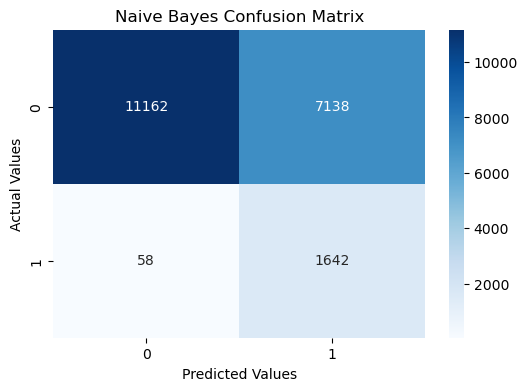

In [53]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.title("Naive Bayes Confusion Matrix")

plt.show()